# Practical session 3 — Hypothesis spaces, feature representations and model generalization

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

warnings.filterwarnings("ignore")
np.random.seed(42)

## Dataset

In [2]:
df = pd.DataFrame({
    "Student": [f"S{i}" for i in range(1, 11)],
    "Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Score": [42, 48, 55, 59, 66, 70, 78, 81, 89, 91],
})
X = df[["Hours"]].values
y = df["Score"].values
X_plot = np.linspace(1, 10, 300).reshape(-1, 1)
loo = LeaveOneOut()


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def loocv_rmse(model):
    s = cross_val_score(model, X, y, cv=loo, scoring="neg_mean_squared_error")
    return np.sqrt(-s.mean())


def poly_lr(d):
    return Pipeline([("poly", PolynomialFeatures(d, include_bias=False)),
                     ("lr", LinearRegression())])


def poly_reg(d, reg):
    return Pipeline([("poly", PolynomialFeatures(d, include_bias=False)),
                     ("scaler", StandardScaler()),
                     ("reg", reg)])

## Part A

=== Dataset ===
  Student  Hours  Score
0      S1      1     42
1      S2      2     48
2      S3      3     55
3      S4      4     59
4      S5      5     66
5      S6      6     70
6      S7      7     78
7      S8      8     81
8      S9      9     89
9     S10     10     91
          Hours      Score
count  10.00000  10.000000
mean    5.50000  67.900000
std     3.02765  16.907921
min     1.00000  42.000000
25%     3.25000  56.000000
50%     5.50000  68.000000
75%     7.75000  80.250000
max    10.00000  91.000000
Correlation: 0.9973

=== Part A ===
                           Model  Training RMSE  Training R2
               Linear Regression         1.1672       0.9947
Polynomial Regression (degree 2)         1.0435       0.9958
Polynomial Regression (degree 3)         1.0211       0.9959


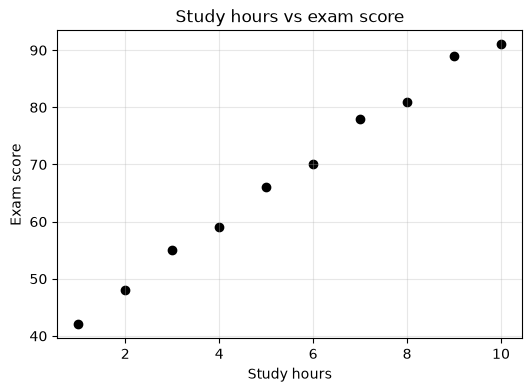

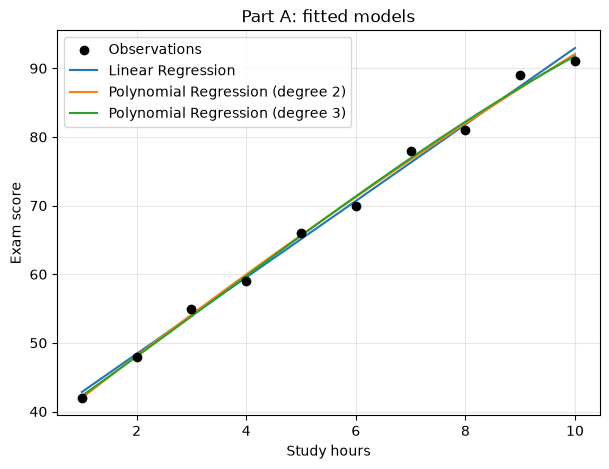

In [3]:
print("=== Dataset ===")
print(df)
print(df[["Hours", "Score"]].describe())
print("Correlation:", np.corrcoef(X.ravel(), y)[0, 1].round(4))

plt.figure(figsize=(6, 4))
plt.scatter(X, y, color="black")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Study hours vs exam score")
plt.grid(alpha=.3)
plt.savefig("A1_scatter.png", dpi=150, bbox_inches="tight")

models_A = {"Linear Regression": poly_lr(1),
            "Polynomial Regression (degree 2)": poly_lr(2),
            "Polynomial Regression (degree 3)": poly_lr(3)}

rows = []
plt.figure(figsize=(7, 5))
plt.scatter(X, y, color="black", label="Observations", zorder=3)
for name, m in models_A.items():
    m.fit(X, y)
    pred = m.predict(X)
    rows.append([name, rmse(y, pred), r2_score(y, pred)])
    plt.plot(X_plot, m.predict(X_plot), label=name)
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Part A: fitted models")
plt.legend()
plt.grid(alpha=.3)
plt.savefig("A3_models.png", dpi=150, bbox_inches="tight")

tab_A = pd.DataFrame(rows, columns=["Model", "Training RMSE", "Training R2"])
print("\n=== Part A ===")
print(tab_A.round(4).to_string(index=False))

## Part B


=== Part B ===
 Degree  Training RMSE  LOOCV RMSE
      1         1.1672      1.5486
      2         1.0435      1.5728
      3         1.0211      2.0620
      5         0.8977      3.5670
      9         2.7957     34.3697
Best degree (lowest LOOCV RMSE): 1


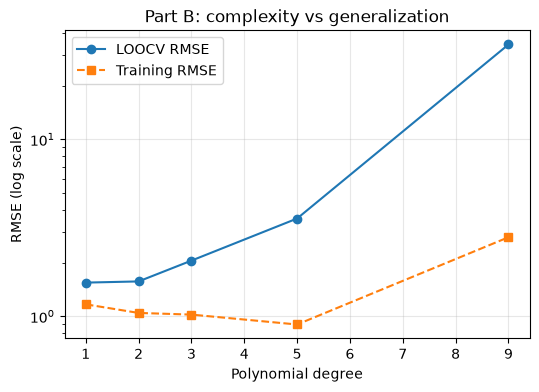

In [4]:
degrees = [1, 2, 3, 5, 9]
rows = []
for d in degrees:
    m = poly_lr(d).fit(X, y)
    rows.append([d, rmse(y, m.predict(X)), loocv_rmse(poly_lr(d))])
tab_B = pd.DataFrame(rows, columns=["Degree", "Training RMSE", "LOOCV RMSE"])
print("\n=== Part B ===")
print(tab_B.round(4).to_string(index=False))
print("Best degree (lowest LOOCV RMSE):",
      int(tab_B.loc[tab_B["LOOCV RMSE"].idxmin(), "Degree"]))

plt.figure(figsize=(6, 4))
plt.plot(tab_B["Degree"], tab_B["LOOCV RMSE"], "o-", label="LOOCV RMSE")
plt.plot(tab_B["Degree"], tab_B["Training RMSE"], "s--", label="Training RMSE")
plt.yscale("log")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (log scale)")
plt.title("Part B: complexity vs generalization")
plt.legend()
plt.grid(alpha=.3)
plt.savefig("B_loocv_vs_degree.png", dpi=150, bbox_inches="tight")

## Part C

In [5]:
print("\n=== Part C.1: feature representations (LOOCV RMSE) ===")
for d, label in [(1, "x"), (3, "x, x^2, x^3"), (5, "x ... x^5")]:
    print(f"{label:12s}: {loocv_rmse(poly_reg(d, LinearRegression())):.4f}")

alphas = [0.01, 0.1, 1, 10]
rows = []
for name, cls in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        reg = cls(alpha=a, max_iter=100000) if name == "Lasso" else cls(alpha=a)
        rows.append([name, a, loocv_rmse(poly_reg(5, reg))])
tab_C_alpha = pd.DataFrame(rows, columns=["Model", "alpha", "LOOCV RMSE"])
print("\n=== Part C.2: regularization (degree 5) ===")
print(tab_C_alpha.round(4).to_string(index=False))

best_ridge_a = tab_C_alpha[tab_C_alpha.Model == "Ridge"].sort_values("LOOCV RMSE").iloc[0]["alpha"]
best_lasso_a = tab_C_alpha[tab_C_alpha.Model == "Lasso"].sort_values("LOOCV RMSE").iloc[0]["alpha"]

def best_ridge():
    return poly_reg(5, Ridge(alpha=best_ridge_a))

def best_lasso():
    return poly_reg(5, Lasso(alpha=best_lasso_a, max_iter=100000))

tab_C = pd.DataFrame([
    ["Linear Regression", 1, "None", loocv_rmse(poly_reg(1, LinearRegression()))],
    ["Polynomial Regression", 3, "None", loocv_rmse(poly_reg(3, LinearRegression()))],
    ["Polynomial Regression", 5, "None", loocv_rmse(poly_reg(5, LinearRegression()))],
    [f"Ridge Regression (alpha={best_ridge_a})", 5, "L2", loocv_rmse(best_ridge())],
    [f"Lasso Regression (alpha={best_lasso_a})", 5, "L1", loocv_rmse(best_lasso())],
], columns=["Model", "Feature Degree", "Regularization", "LOOCV RMSE"])
print("\n=== Part C.3 ===")
print(tab_C.round(4).to_string(index=False))


=== Part C.1: feature representations (LOOCV RMSE) ===
x           : 1.5486
x, x^2, x^3 : 2.0620
x ... x^5   : 3.7070

=== Part C.2: regularization (degree 5) ===
Model  alpha  LOOCV RMSE
Ridge   0.01      2.1442
Ridge   0.10      1.8071
Ridge   1.00      3.5735
Ridge  10.00      7.2820
Lasso   0.01      1.7654
Lasso   0.10      1.6223
Lasso   1.00      1.9187
Lasso  10.00     11.8773

=== Part C.3 ===
                       Model  Feature Degree Regularization  LOOCV RMSE
           Linear Regression               1           None      1.5486
       Polynomial Regression               3           None      2.0620
       Polynomial Regression               5           None      3.7070
Ridge Regression (alpha=0.1)               5             L2      1.8071
Lasso Regression (alpha=0.1)               5             L1      1.6223


## Part D: final comparison


=== Part D: final summary ===
                        Model  Training RMSE  LOOCV RMSE  Gap (LOOCV - Train)
            Linear Regression         1.1672      1.5486               0.3814
     Lasso (deg 5, alpha=0.1)         1.0656      1.6223               0.5567
     Ridge (deg 5, alpha=0.1)         1.0865      1.8071               0.7206
Polynomial Regression (deg 3)         1.0211      2.0620               1.0409
                    SVR (RBF)         1.0383      2.4973               1.4590
                Random Forest         1.5868      4.6458               3.0590
                Decision Tree         0.0000      5.8566               5.8566
                    KNN (k=3)         2.6562      6.1761               3.5199

Best generalization: Linear Regression

=== Fitted predictions vs observations ===
 Hours  Observed  Linear Regression  Polynomial Regression (deg 3)  Ridge (deg 5, alpha=0.1)  Lasso (deg 5, alpha=0.1)
     1        42              42.84                          42.

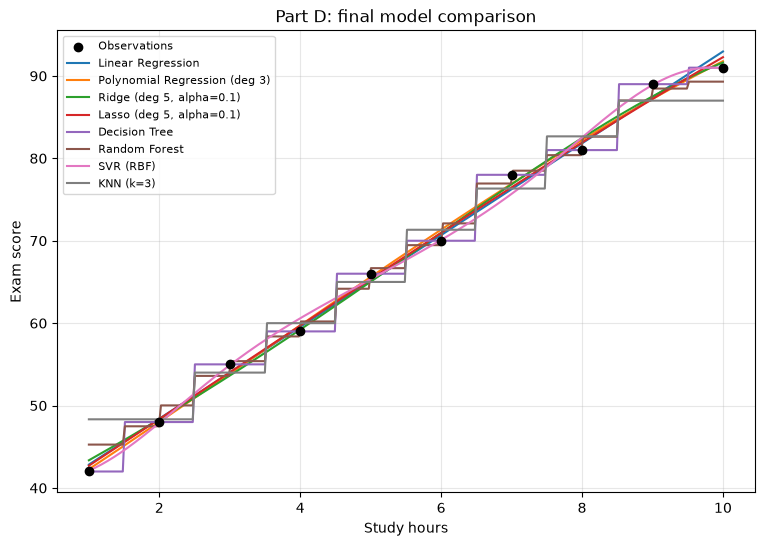

In [ ]:
best_deg = int(tab_B.loc[tab_B["LOOCV RMSE"].idxmin(), "Degree"])
final_models = {
    "Linear Regression": poly_lr(1),
    "Polynomial Regression (deg 3)": poly_lr(3),
    f"Ridge (deg 5, alpha={best_ridge_a})": best_ridge(),
    f"Lasso (deg 5, alpha={best_lasso_a})": best_lasso(),
    
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=100)),
    "KNN (k=3)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=3)),
}

rows = []
plt.figure(figsize=(9, 6))
plt.scatter(X, y, color="black", label="Observations", zorder=3)
for name, m in final_models.items():
    m.fit(X, y)
    rows.append([name, rmse(y, m.predict(X)), loocv_rmse(m)])
    plt.plot(X_plot, m.predict(X_plot), label=name, lw=1.5)
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Part D: final model comparison")
plt.legend(fontsize=8)
plt.grid(alpha=.3)
plt.savefig("D_final_comparison.png", dpi=150, bbox_inches="tight")

tab_D = pd.DataFrame(rows, columns=["Model", "Training RMSE", "LOOCV RMSE"])
tab_D["Gap (LOOCV - Train)"] = tab_D["LOOCV RMSE"] - tab_D["Training RMSE"]
tab_D = tab_D.sort_values("LOOCV RMSE").reset_index(drop=True)
print("\n=== Part D: final summary ===")
print(tab_D.round(4).to_string(index=False))
print("\nBest generalization:", tab_D.iloc[0]["Model"])


pred_tab = pd.DataFrame({"Hours": X.ravel(), "Observed": y})
for name in list(final_models)[:4]:
    pred_tab[name] = final_models[name].predict(X).round(2)
print("\n=== Fitted predictions vs observations ===")
print(pred_tab.to_string(index=False))

## Conclusion

CONCLUSION
- Complexity: training RMSE decreases monotonically as the polynomial degree grows
  (degree 9 interpolates the 10 points), but LOOCV RMSE rises for high degrees:
  the extra flexibility fits noise (overfitting).
- Feature representation: the data are almost linear with slight curvature, so
  x (and at most x^2, x^3) are enough; x^4, x^5 add variance, not information.
- Regularization: Ridge/Lasso with a suitable alpha shrinks coefficients and
  brings the degree-5 model's LOOCV RMSE back down, but it does not beat a
  simple low-degree model here.
- Best balance: the model with the lowest LOOCV RMSE and a small train/LOOCV gap
  (see the summary table above).

In [7]:
plt.show()